In [142]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

In [143]:
waves = pd.read_csv('waves_2023.txt', sep=r'\s+')

In [144]:
# get undesired variables out 
waves = waves.drop(['WDIR','WSPD','GST','PRES','ATMP','DEWP','VIS','TIDE'], axis=1)
waves.head()

# get rid of missing data
waves = waves[waves['WVHT'] < 99]
waves = waves[waves['DPD'] < 99]
waves = waves[waves['APD'] < 99]
waves = waves[waves['MWD'] < 999]

In [145]:
# no need for time in PCA
waves_comp = waves.iloc[:,5:]
waves_comp.head(2)

,WVHT,DPD,APD,MWD,WTMP
0,1.12,12.50,7.69,269,15.3
1,1.16,11.76,7.34,272,15.3


In [146]:
pca = PCA(n_components=5)
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
scaled_df=waves_comp.copy()
scaled_df=pd.DataFrame(scaler.fit_transform(scaled_df), columns=scaled_df.columns)
df_scaled = pca.fit_transform(scaled_df)

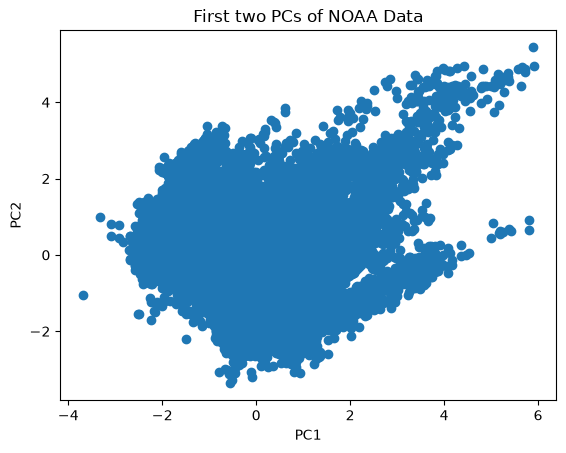

In [147]:
plt.subplots()
plt.scatter(df_scaled[:, 0], df_scaled[:, 1])
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('First two PCs of NOAA Data')
plt.show()

In [148]:
# how many PCs needed?
# Scree plot

In [149]:
var = pca.explained_variance_ratio_

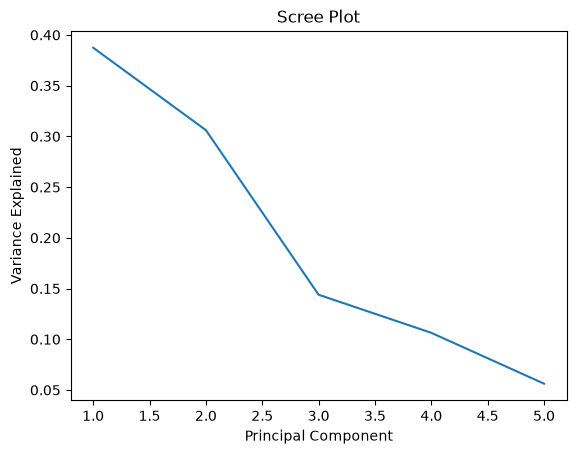

In [150]:
PC_values = np.arange(pca.n_components_) + 1
plt.plot(PC_values, pca.explained_variance_ratio_)
plt.title('Scree Plot')
plt.xlabel('Principal Component')
plt.ylabel('Variance Explained')
plt.show()

In [151]:
print(pca.explained_variance_ratio_)

[0.38740951 0.30614216 0.14389315 0.10634805 0.05620713]


In [152]:
# The first two PCs explain a good portion of the variance of the data.

In [153]:
num_pcs = 5
for pc in range(num_pcs):
    ranked_loadings = np.argsort(np.abs(pca.components_[pc]))[::-1][:1]
    print(f"Top variable for PC{pc+1}:")
    print(df_z.columns[ranked_loadings])
    print("\n")

Top variable for PC1:
Index(['MWD'], dtype='str')


Top variable for PC2:
Index(['DPD'], dtype='str')


Top variable for PC3:
Index(['WTMP'], dtype='str')


Top variable for PC4:
Index(['WVHT'], dtype='str')


Top variable for PC5:
Index(['DPD'], dtype='str')




In [154]:
# WVHT=Height, DPD=Dominant wave period, APD=Average wave period, MWD=direction waves at DPD, WTMP=temperature
# The most important varibles for PCs 1-5 are wave direction, dominant wave period, wave temperature, wave height and dominant wave period respectively

In [155]:
# What does the good or bad performance of a linear dimensionality reduction method tell you about this dataset?
    # The good performance tells us that the variance/trends in the data set are conserved with reduction.
    # I think this means that we can use the PCs to make predictions.

In [156]:
# K-means clustering
from sklearn.cluster import KMeans

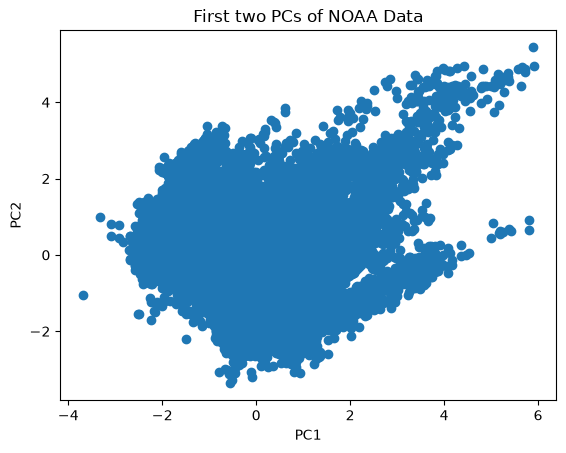

In [157]:
# Now, cluster in that PC space to find clusters in the reduced dimensional space.
    # Plot PC1 vs PC2.
plt.subplots()
plt.scatter(df_scaled[:, 0], df_scaled[:, 1])
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('First two PCs of NOAA Data')
plt.show()

In [158]:
#Perform K-means on the principal component transformed data 

pca2 = PCA(n_components=5)
X = pca2.fit_transform(scaled_df)

In [159]:
cluster = [] # sum of square distances 
for i in range (1,11):
    kmeans_pca = KMeans(n_clusters=i, random_state=42, n_init='auto').fit(X)
    cluster.append(kmeans_pca.inertia_)
number = ['1','2','3','4','5','6','7','8','9','10']

Text(0, 0.5, 'Sum of square distances')

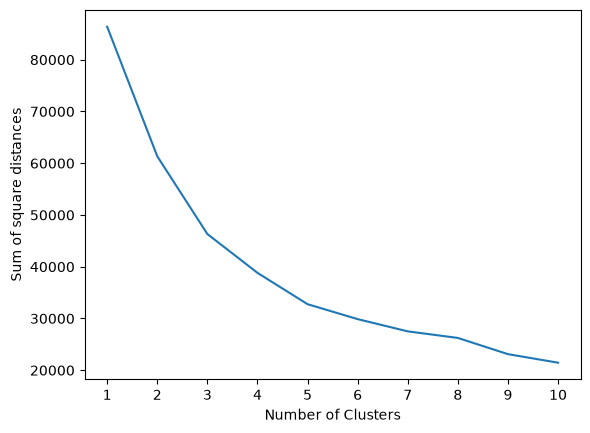

In [160]:
# Plot the Sum of squared distances as a function of the number of clusters for 1 to 10 clusters.

plt.plot(number, cluster)
plt.xlabel('Number of Clusters')
plt.ylabel('Sum of square distances')


In [161]:
#How many clusters are the right choice, why?
    # The right number of clusters is in the range of 3-4, around this point is where the elbow of the graph is.
    # The sum of square distances levels off after this point, afterwards the sequential clusters do not capture much variablility. 

In [162]:
# Plot PC1 vs PC2, add the points of the cluster centers.

In [172]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init='auto').fit(X)
kmeans

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",3
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",42
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",'auto'
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](3, 5)","[

In [183]:
center = kmeans.cluster_centers_
center

array([[-1.44637358,  0.53477714, -0.112831  ,  0.30691677, -0.09041816],
       [ 0.46644344, -1.05014009,  0.08201878, -0.19945926,  0.01712129],
       [ 1.56949784,  1.20661087,  0.0295319 , -0.12846868,  0.12262352]])

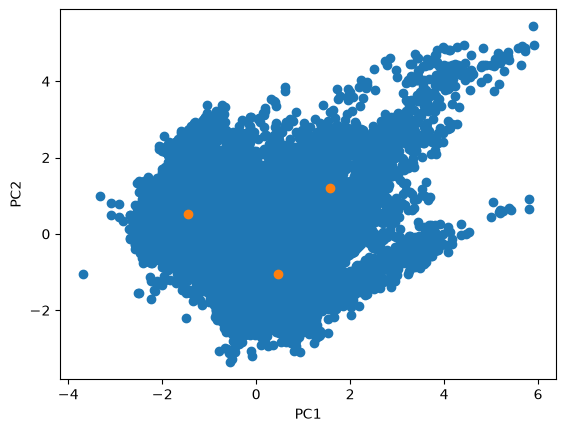

In [185]:
plt.subplots()
plt.scatter(df_scaled[:, 0], df_scaled[:, 1])
plt.scatter(center[0:3, 0],center[0:3, 1])
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.show()

In [186]:
# Does this clustering make sense with what you can see with your eyes?

In [ ]:
# It makes sense, the points seem to be distributed evenly among the cluster.